# Testing what cannot be asserted — unit tests, a calibrated judge, and a release gate with error bars

**Course** MLAIDP · **Module 9 — Testing, Validation, and Continuous Improvement**
· **When:** after slide 38 (*Evaluation prompt engineering — crafting effective instructions for consistent
assessment*), before slide 39 (*End-to-end RAG system validation — comprehensive testing for production readiness*);
§4 revisits slides 19–20 (quality gates, regression testing)
· **Kernel** MLAIDP (Python 3.12) · your AWS credentials (`AWS_PROFILE` or the default chain), us-east-1
· **Runtime** about 1½ minutes of cell time after §0 (≈ 520 model calls, 4 in parallel) · **Cost per run** about
$0.04 (notebook) + about $0.20 (two evaluation jobs, started once; estimate)

**What you'll learn**
- Split the system into what **can** be asserted (request building, parsers, output contracts — plain unit tests that run
  in milliseconds) and what cannot (is this answer *right*?) — and see how far a deterministic oracle reaches.
- **Calibrate an LLM judge against human labels**: agreement, **Cohen's kappa with a bootstrap interval**, and the
  disagreements that show where the rubric is ambiguous — a naive "rate 1–5" judge against a hardened rubric.
- Measure the judge's **position bias** (swap A/B) and **verbosity bias** (padded vs plain), and the mitigation that
  removes them: count a win only if it survives the swap, allow a tie, say "length is not quality".
- Run a **release gate** for a prompt change with rules written *before* the test: a **cluster bootstrap CI** on the
  score difference (non-inferiority margin), output contracts and an output-token budget.
- Read the managed version — two **Amazon Bedrock Evaluations** jobs (LLM-as-a-judge on your own responses, built-in
  metrics + a **custom metric**) created in code — and gate on its per-record scores with the same statistics.

> **Resources:** S3 bucket `mlaidp2-m09-<run id>` (datasets + job output), IAM role `mlaidp2-m09-eval-role`, two
> evaluation jobs `mlaidp2-m09-<run id>-support-v1` / `-v2`. §0 Prep creates them in about 30 s; the jobs then need
> **10–30 minutes** — run §0 at least 35 minutes before class. The cleanup section deletes everything.

![M09 at a glance: unit tests and contracts (§1), a calibrated judge (§2) without position or verbosity bias (§3), a release gate with error bars (§4), Bedrock Evaluations (§5)](../assets/diagrams/m09_overview.svg)

**How to read this notebook**
| Marker | Meaning |
|---|---|
| 💡 **Concept** | the idea behind the next cells, in a few lines |
| 🔑 **Key code** | the lines worth reading closely; in the code they are marked `# ▶ KEY` |
| 📊 **How to read this** | what the output means and what to look for |
| ✅ **Takeaway** | the one thing to remember from a section |

## §0 Setup

In [1]:
import sys, json, math, random, re, statistics, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

sys.path.insert(0, "../common")
import mlaidp as m
from botocore.exceptions import ClientError

RID = m.setup_banner("M09")
brt, bedrock, s3, iam = m.client("bedrock-runtime"), m.client("bedrock"), m.client("s3"), m.client("iam")
ACCOUNT = m.account()

GENERATOR = m.NOVA_LITE                 # the support assistant under test
# judges: a strong one from another model family than the generator (self-preference, slide 36) - and with 1,000
# requests/min in this account vs 50 for Nova Pro - and a cheap one that is the generator's own model
JUDGES = [m.MISTRAL_L3, m.NOVA_LITE]
BUCKET, ROLE = f"mlaidp2-m09-{RID}", "mlaidp2-m09-eval-role"
JOBS = {"v1": f"mlaidp2-m09-{RID}-support-v1", "v2": f"mlaidp2-m09-{RID}-support-v2"}
SPEND = Counter()                       # $ per section, from the usage block of every call

def converse_text(model_id: str, prompt: str, *, system: str | None = None, max_tokens: int = 200,
                  temperature: float = 0.0, section: str = "") -> tuple[str, dict]:
    """One Converse call -> (text, usage). Judges run at temperature 0 so repeated scoring is stable."""
    req = dict(modelId=model_id, messages=[{"role": "user", "content": [{"text": prompt}]}],
               inferenceConfig={"maxTokens": max_tokens, "temperature": temperature})
    if system:
        req["system"] = [{"text": system}]
    r = brt.converse(**req)
    SPEND[section] += m.usd(model_id, r["usage"])                   # ▶ KEY: every call is costed from its usage block
    return m.text_of(r), r["usage"]

def pmap(fn, items, workers: int = 4) -> list:
    with ThreadPoolExecutor(workers) as pool:       # <= 4 parallel calls: on-demand quotas of a new account are small
        return list(pool.map(fn, items))

account 1143…  ·  us-east-1  ·  credentials AWS_PROFILE  ·  run id 1023aad9


The system under test: AnyCompany Insurance's support assistant answers questions about home policy HP-2026 from a
facts block in its system prompt. **v1** is in production; **v2** is a "small" change from the customer-experience
team: *always apologize and thank the customer first*. The golden set has 20 questions with reference answers.

In [2]:
POLICY_FACTS = (
    "Facts (home policy HP-2026): deductibles - glass breakage 100 USD, standard 500 USD, storm 1,000 USD, escape of "
    "water 750 USD, theft 250 USD. Report claims within 30 days of the incident; upload photos within 7 days of "
    "reporting. Flood (water from outside: river, sea, rain run-off) is covered only with the flood add-on. If the home "
    "is unlivable we pay a hotel for up to 30 nights, at most 150 USD per night. Jewelry is covered up to 1,500 USD in "
    "total per claim, only after forced entry. Keep damaged items until the adjuster has seen them (you may move "
    "them outside). A burst pipe inside the home is escape of water and covered; the failed pipe itself is not. "
    "Settlement is paid within 10 business days of agreeing the amount. Storm damage to fences and gates is covered "
    "up to 2,000 USD. Earthquake is covered. Wear and tear, rust and mould are not covered. A home empty for more "
    "than 60 days is unoccupied: only fire, lightning and earthquake are then covered. A falling tree is covered "
    "including its removal. Emergency boarding-up of a broken window is covered. The policy can be cancelled within "
    "14 days for a full refund. The claims line is open 24/7.")
PROMPTS = {
    "v1": f"You are AnyCompany Insurance's support assistant. Answer in at most two sentences. {POLICY_FACTS}",
    "v2": ("You are AnyCompany Insurance's support assistant. Always start by apologizing for the inconvenience and "
           "thanking the customer for their loyalty, then reassure them that we will take care of everything. Keep it "
           f"short. {POLICY_FACTS}"),
}

In [3]:
GOLDEN = [  # (question, reference answer)
    ("What is the deductible for a broken window?", "100 USD (glass breakage deductible)."),
    ("How long do I have to report a claim?", "30 days from the incident."),
    ("Is flood water from a river covered?", "No, only if the flood add-on is in the schedule."),
    ("How many nights of hotel do you pay if the house is unlivable?", "Up to 30 nights, at most 150 USD per night."),
    ("Is jewelry covered if it is stolen?", "Yes, after forced entry, up to 1,500 USD in total per claim."),
    ("When must I upload photos of the damage?", "Within 7 days of reporting the claim."),
    ("What is the deductible for storm damage?", "1,000 USD."),
    ("Can I throw away damaged items before the adjuster comes?",
     "No - keep them until the adjuster has seen them; you may move them outside."),
    ("Is a burst pipe inside the house covered?", "Yes, as escape of water; the failed pipe itself is not covered."),
    ("How quickly is a settlement paid?", "Within 10 business days of agreeing the amount."),
    ("What is the deductible if my house is burgled?", "250 USD (theft deductible)."),
    ("The storm knocked down my garden fence. Is that covered?",
     "Yes, storm damage to fences and gates is covered up to 2,000 USD."),
    ("Is earthquake damage covered?", "Yes, earthquake is covered."),
    ("My bathroom has mould from years of damp. Can I claim?", "No - mould, damp and gradual damage are not covered."),
    ("I was abroad for 3 months and a pipe burst. Am I covered?",
     "No - after 60 days the home is unoccupied; only fire, lightning and earthquake are covered."),
    ("A tree fell on my roof. Do you pay to remove it?", "Yes, falling trees are covered including removal."),
    ("Do you pay for boarding up a broken window tonight?", "Yes, emergency boarding-up is covered."),
    ("Can I cancel my new policy and get my money back?", "Yes, within 14 days for a full refund."),
    ("What is the deductible for a burst pipe?", "750 USD (escape of water deductible)."),
    ("Can I call to report a claim on Sunday night?", "Yes, the claims line is open 24/7."),
]
print(f"{len(GOLDEN)} golden questions · prompt v1 {len(PROMPTS['v1'])} chars · v2 {len(PROMPTS['v2'])} chars")

20 golden questions · prompt v1 1241 chars · v2 1375 chars


## §0 Prep — start the Amazon Bedrock Evaluations jobs (run ≥ 35 min before class)
A managed **LLM-as-a-judge** job with **bring-your-own inference responses**: we generate the answers of v1 and v2
ourselves (temperature 0), write them as JSONL, and the job only *judges* them — the same configuration for both versions
makes the reports comparable (slide 20). First the bucket and a least-privilege service role: the trust policy is pinned
to our account and to evaluation jobs (confused-deputy protection); the permissions name one bucket and one judge model.

> 💡 **Concept — Amazon Bedrock Evaluations, model-as-a-judge.** `CreateEvaluationJob` runs an asynchronous job
> that reads a **JSONL dataset from S3**, has an **evaluator model** score every record on the metrics you choose, and
> writes per-record scores plus an explanation back to S3. With **bring your own inference responses**
> (`precomputedInferenceSource`) each record already contains the answer (`modelResponses`), so the job does not call
> the model under test at all — it only judges. That is what lets you evaluate any system (a RAG pipeline, an agent, a
> model outside Bedrock) and compare two versions with exactly the same judge. The job runs as an IAM **service
> role** that Bedrock assumes: it reads the dataset, invokes the evaluator model and writes the results.

> 🔑 **Key code** — the trust policy's `aws:SourceArn` pattern `evaluation-job/*` (only evaluation jobs of this
> account may assume the role); the permission policy lists one bucket and the Nova Pro model / inference profile;
> `put_bucket_cors` is only for the console wizard, which reads the dataset from the browser.

In [4]:
JUDGE_PROFILE = m.NOVA_PRO          # a judge model that Bedrock Evaluations supports; the job paces its own calls

def ensure_bucket() -> None:
    try:
        s3.head_bucket(Bucket=BUCKET); print(f"adopted bucket {BUCKET}")
    except ClientError:
        s3.create_bucket(Bucket=BUCKET); s3.get_waiter("bucket_exists").wait(Bucket=BUCKET); print(f"created bucket {BUCKET}")
    s3.put_public_access_block(Bucket=BUCKET, PublicAccessBlockConfiguration={k: True for k in (
        "BlockPublicAcls", "IgnorePublicAcls", "BlockPublicPolicy", "RestrictPublicBuckets")})
    s3.put_bucket_tagging(Bucket=BUCKET, Tagging={"TagSet": [{"Key": k, "Value": v} for k, v in m.TAGS.items()]})
    # the console's job wizard reads the dataset from your browser -> the bucket needs CORS (documented requirement)
    s3.put_bucket_cors(Bucket=BUCKET, CORSConfiguration={"CORSRules": [{"AllowedHeaders": ["*"], "AllowedOrigins": ["*"],
        "AllowedMethods": ["GET", "PUT", "POST", "DELETE"], "ExposeHeaders": ["Access-Control-Allow-Origin"]}]})

ensure_bucket()

created bucket mlaidp2-m09-1023aad9


In [5]:
def ensure_role() -> str:
    trust = {"Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Principal": {"Service": "bedrock.amazonaws.com"},
             "Action": "sts:AssumeRole", "Condition": {"StringEquals": {"aws:SourceAccount": ACCOUNT},
             # ▶ KEY: only evaluation jobs of this account may assume the role (confused deputy)
             "ArnLike": {"aws:SourceArn": f"arn:aws:bedrock:{m.REGION}:{ACCOUNT}:evaluation-job/*"}}}]}
    # ▶ KEY: least privilege - one bucket, one judge model
    policy = {"Version": "2012-10-17", "Statement": [
        {"Effect": "Allow", "Action": ["s3:GetObject", "s3:PutObject", "s3:ListBucket", "s3:GetBucketLocation"],
         "Resource": [f"arn:aws:s3:::{BUCKET}", f"arn:aws:s3:::{BUCKET}/m09/*"]},
        {"Effect": "Allow", "Action": ["bedrock:InvokeModel", "bedrock:CreateModelInvocationJob",
                                         "bedrock:StopModelInvocationJob", "bedrock:GetInferenceProfile"],
         "Resource": ["arn:aws:bedrock:*::foundation-model/amazon.nova-pro-v1:0",       # the profile routes to any US Region
                      f"arn:aws:bedrock:{m.REGION}:{ACCOUNT}:inference-profile/{JUDGE_PROFILE}"]}]}
    try:
        arn = iam.get_role(RoleName=ROLE)["Role"]["Arn"]; print(f"adopted role {ROLE}")
    except ClientError:
        arn = iam.create_role(RoleName=ROLE, AssumeRolePolicyDocument=json.dumps(trust),
                              Tags=[{"Key": k, "Value": v} for k, v in m.TAGS.items()])["Role"]["Arn"]
        print(f"created role {ROLE}")
    iam.update_assume_role_policy(RoleName=ROLE, PolicyDocument=json.dumps(trust))
    iam.put_role_policy(RoleName=ROLE, PolicyName="eval-job", PolicyDocument=json.dumps(policy))
    return arn

ROLE_ARN = ensure_role()

created role mlaidp2-m09-eval-role


The job definition. Built-in metrics ship with judge prompts AWS has tested; the **custom metric** brings our own rubric and
rating scale (slide 38: instructions, a scale with a definition per value, template variables `{{prompt}}` and
`{{prediction}}`). The job is **adopted** if one with this name is running or finished; a failed one is replaced.

> 💡 **Concept — built-in vs custom metrics.** Built-in metrics (`Builtin.Correctness`, `Builtin.Completeness`,
> `Builtin.Helpfulness`, `Builtin.ProfessionalStyleAndTone`, …) come with judge prompts AWS wrote and tested. A
> **custom metric** is your own rubric: `instructions` with template variables the service fills in per record
> (`{{prompt}}` = the question, `{{prediction}}` = the answer under test) and a `ratingScale` where every value has a
> definition. The service normalises every score to 0–1 in the report, whatever scale you used.

> 🔑 **Key code** — in `job_request`: `metricNames` lists built-ins **and** the custom metric's name;
> `customMetricConfig.customMetrics[].customMetricDefinition` carries `instructions` + `ratingScale`;
> `inferenceConfig.models[].precomputedInferenceSource.inferenceSourceIdentifier` must equal the `modelIdentifier`
> written into the dataset records (`support-v1` / `support-v2`).

In [6]:
EMPATHY = ("You are evaluating an answer from an insurance customer support assistant.\nCustomer message: {{prompt}}\n"
           "Answer: {{prediction}}\n"
           "Does the answer acknowledge the customer's situation in a natural, specific way WITHOUT empty, repetitive or "
           "scripted apologies and filler? Scripted phrases such as 'we apologize for the inconvenience' or 'thank you for "
           "your loyalty' that do not fit the question make the answer Poor. Rate it.")
METRICS = ["Builtin.Correctness", "Builtin.Completeness", "Builtin.Helpfulness", "Builtin.ProfessionalStyleAndTone", "Empathy"]

def job_request(label: str, name: str, dataset_uri: str) -> dict:
    evaluator = {"bedrockEvaluatorModels": [{"modelIdentifier": JUDGE_PROFILE}]}
    return dict(
        jobName=name, jobDescription=f"MLAIDP M09 support prompt {label}", roleArn=ROLE_ARN, applicationType="ModelEvaluation",
        evaluationConfig={"automated": {
            "datasetMetricConfigs": [{"taskType": "General", "metricNames": METRICS,
                                      "dataset": {"name": f"golden-{label}", "datasetLocation": {"s3Uri": dataset_uri}}}],
            "evaluatorModelConfig": evaluator,
            # ▶ KEY: our own rubric as a metric - instructions with {{prompt}}/{{prediction}} and a defined scale
            "customMetricConfig": {"evaluatorModelConfig": evaluator, "customMetrics": [{"customMetricDefinition": {
                "name": "Empathy", "instructions": EMPATHY,
                "ratingScale": [{"definition": "Poor", "value": {"floatValue": 0}},
                                {"definition": "Good", "value": {"floatValue": 1}},
                                {"definition": "Excellent", "value": {"floatValue": 2}}]}}]}}},
        # ▶ KEY: bring your own responses - the job only judges, it never calls the model under test
        inferenceConfig={"models": [{"precomputedInferenceSource": {"inferenceSourceIdentifier": f"support-{label}"}}]},
        outputDataConfig={"s3Uri": f"s3://{BUCKET}/m09/results/"},
        jobTags=[{"key": k, "value": v} for k, v in m.TAGS.items()])

cfg = job_request("v1", JOBS["v1"], f"s3://{BUCKET}/m09/datasets/support-v1.jsonl")
custom = cfg["evaluationConfig"]["automated"]["customMetricConfig"]["customMetrics"][0]["customMetricDefinition"]
print(json.dumps({"metricNames": METRICS, "evaluator": JUDGE_PROFILE, "inferenceConfig": cfg["inferenceConfig"],
                  "customMetric": {"name": custom["name"], "ratingScale": {r["definition"]: r["value"]["floatValue"]
                                                                           for r in custom["ratingScale"]}}}, indent=1))

{
 "metricNames": [
  "Builtin.Correctness",
  "Builtin.Completeness",
  "Builtin.Helpfulness",
  "Builtin.ProfessionalStyleAndTone",
  "Empathy"
 ],
 "evaluator": "us.amazon.nova-pro-v1:0",
 "inferenceConfig": {
  "models": [
   {
    "precomputedInferenceSource": {
     "inferenceSourceIdentifier": "support-v1"
    }
   }
  ]
 },
 "customMetric": {
  "name": "Empathy",
  "ratingScale": {
   "Poor": 0,
   "Good": 1,
   "Excellent": 2
  }
 }
}


Adopt or start the two jobs. A dataset record is one JSON line: `prompt`, `referenceResponse`, and `modelResponses`
with the answer and the source name.

> 🔑 **Key code** — `find_job` pages through `list_evaluation_jobs` and adopts a running or finished job (names must
> be unique, so a failed job is replaced by `name-rNNNNN`); `write_dataset` writes the JSONL; `create_evaluation_job`
> is wrapped in `m.retry` because a role created seconds ago is not yet assumable by the service.

> ⏱️ On the first run this cell prints nothing for ≈ 15–25 s (40 answers generated for the datasets); adopting is instant.

In [7]:
def find_job(name: str) -> dict | None:
    """Newest job with this name (or a replacement name-rNNNNN) that is running or finished. Paginated."""
    found = [j for page in bedrock.get_paginator("list_evaluation_jobs").paginate(nameContains=name)
             for j in page["jobSummaries"] if j["jobName"] == name or j["jobName"].startswith(name + "-r")]
    alive = [j for j in found if j["status"] in ("InProgress", "Completed")]
    return max(alive, key=lambda j: j["creationTime"]) if alive else None

def write_dataset(label: str) -> str:
    """BYO responses: one JSONL record per golden question - prompt, reference, the response and who produced it."""
    answers = pmap(lambda g: converse_text(GENERATOR, g[0], system=PROMPTS[label], section="§0")[0], GOLDEN)
    # ▶ KEY: the BYO-response record format - modelIdentifier must match inferenceSourceIdentifier
    rows = [{"prompt": q, "referenceResponse": ref,
             "modelResponses": [{"response": a, "modelIdentifier": f"support-{label}"}]} for (q, ref), a in zip(GOLDEN, answers)]
    key = f"m09/datasets/support-{label}.jsonl"
    s3.put_object(Bucket=BUCKET, Key=key, Body="\n".join(json.dumps(r) for r in rows).encode())
    return f"s3://{BUCKET}/{key}"

for label, name in JOBS.items():
    job = find_job(name)
    if job:
        print(f"adopted {job['jobName']}: {job['status']}")
        continue
    stale = any(j["jobName"] == name for j in bedrock.list_evaluation_jobs(nameContains=name)["jobSummaries"])
    req = job_request(label, f"{name}-r{int(time.time()) % 100000}" if stale else name, write_dataset(label))
    # ▶ KEY: start the asynchronous job; retried while the new role propagates
    arn = m.retry(lambda: bedrock.create_evaluation_job(**req)["jobArn"], when="AccessDenied|role|assume", tries=10, delay=6)
    print(f"started {req['jobName']} (about 10-30 min)")

started mlaidp2-m09-1023aad9-support-v1 (about 10-30 min)


started mlaidp2-m09-1023aad9-support-v2 (about 10-30 min)


## 1 · Test what *can* be asserted
The bottom of the testing pyramid you'll see next (slide 39): the code around the model is ordinary code. The request
builder, the judge-output parser and the **output contract** (numbers from the reference must appear, length budget, no promises) are
deterministic — plain unit tests, run on every commit, in milliseconds, for $0.

> 💡 **Concept — an oracle.** A test needs an *oracle*: something that decides pass/fail. For the code around the
> model the oracle is exact (`parse_verdict('{"score": 7}')` must be `None`). For model output a **partial oracle**
> still works where the answer has a checkable part — every amount and deadline in the reference must appear in the
> answer. Where there is nothing checkable ("Is a burst pipe covered?"), only a reader — a human or a judge model —
> can decide. Knowing how much of your golden set each oracle reaches tells you where the judge is unavoidable.

> 🔑 **Key code** — `parse_verdict` **fails closed**: anything that is not an integer score 1–5 becomes `None`
> (later counted as FAIL), never a guess from prose. `contract` returns three booleans: the reference's numbers ⊆ the
> answer's numbers (after removing thousands separators), a word budget, and no promise words.

In [8]:
NUMBER = re.compile(r"\d[\d,]*(?:\.\d+)?")

def build_request(question: str, version: str) -> dict:
    """What the application sends - the code under test, not the model."""
    return {"modelId": GENERATOR, "system": [{"text": PROMPTS[version]}],
            "messages": [{"role": "user", "content": [{"text": question.strip()}]}],
            "inferenceConfig": {"maxTokens": 200, "temperature": 0}}

def parse_verdict(text: str) -> int | None:
    """A judge's JSON verdict -> score 1..5, or None (never guess a score from prose)."""
    j = m.parse_json(text)
    s = j.get("score") if isinstance(j, dict) else None
    if isinstance(s, str) and re.fullmatch(r"\s*\d\s*", s):      # Nova Lite sometimes sends "score": "2"
        s = int(s)
    # ▶ KEY: fail closed - only an integer 1..5 is a score; everything else is None
    return int(s) if isinstance(s, (int, float)) and 1 <= s <= 5 and float(s).is_integer() else None

def numbers(text: str) -> set[str]:
    return {n.replace(",", "").rstrip(".") for n in NUMBER.findall(text)}

def contract(answer: str, reference: str, max_words: int = 60) -> dict[str, bool]:
    # ▶ KEY: a partial oracle - the reference's numbers must be a subset of the answer's numbers
    return {"numbers": numbers(reference) <= numbers(answer),             # every amount/deadline of the reference
            "length": len(answer.split()) <= max_words,
            "no promises": not re.search(r"\bguarantee|\bdefinitely covered|100 ?%", answer, re.I)}

In [9]:
TESTS = []
def test(fn):
    TESTS.append(fn); return fn

@test
def request_keeps_facts_and_trims_input():
    r = build_request("  Is earthquake covered? ", "v1")
    assert POLICY_FACTS in r["system"][0]["text"] and r["messages"][0]["content"][0]["text"] == "Is earthquake covered?"
@test
def parser_reads_fenced_json():          assert parse_verdict('```json\n{"score": 4}\n```') == 4
@test
def parser_rejects_out_of_range():       assert parse_verdict('{"score": 7}') is None and parse_verdict('{"score": 3.5}') is None
@test
def parser_accepts_numeric_string():     assert parse_verdict('{"score": "2"}') == 2 and parse_verdict('{"score": "two"}') is None
@test
def parser_never_guesses_from_prose():   assert parse_verdict("I would give it a 5.") is None
@test
def contract_normalises_thousands():     assert contract("That is 1,000 USD.", "1000 USD")["numbers"]
@test
def contract_flags_promises():           assert not contract("We guarantee you are covered.", "Yes")["no promises"]
@test
def contract_cannot_read_paraphrase():   # documents the oracle's limit: "two weeks" is not "14" to a regex
    assert not contract("Within two weeks.", "Within 14 days")["numbers"]

def run_tests() -> list[dict]:
    rows = []
    for fn in TESTS:
        t0 = time.perf_counter()
        try:
            fn(); ok = "✓ pass"
        except AssertionError:
            ok = "✗ FAIL"
        rows.append({"test": fn.__name__, "result": ok, "ms": (time.perf_counter() - t0) * 1000})
    return rows

m.table(run_tests(), fmt={"ms": "{:.2f}"})

test,result,ms
request_keeps_facts_and_trims_input,✓ pass,0.01
parser_reads_fenced_json,✓ pass,0.09
parser_rejects_out_of_range,✓ pass,0.01
parser_accepts_numeric_string,✓ pass,0.02
parser_never_guesses_from_prose,✓ pass,0.01
contract_normalises_thousands,✓ pass,0.04
contract_flags_promises,✓ pass,0.00
contract_cannot_read_paraphrase,✓ pass,0.00


> 📊 **How to read this** — one row per unit test: its name says what it pins down, **result** must be ✓ for all of
> them, **ms** shows the cost (fractions of a millisecond — these can run on every commit). The last test passes
> *because* the contract fails to read "two weeks" as 14 days: it documents a known limit of the oracle.

Now the same contract against **live model output** (v1, temperature 0). The number check is a real oracle — but only
for the questions whose reference contains a number. Count how much of the golden set it can reach.

In [10]:
V1_ANSWERS = pmap(lambda g: converse_text(GENERATOR, g[0], system=PROMPTS["v1"], section="§1")[0], GOLDEN)
rows = []
for (q, ref), a in zip(GOLDEN, V1_ANSWERS):
    c = contract(a, ref)
    rows.append({"question": q[:46], "answer": a[:70], "oracle": "numbers" if numbers(ref) else "– needs a judge –",
                 **{k: "✓" if v else "✗" for k, v in c.items()}})
m.table(rows)
reach = sum(bool(numbers(ref)) for _, ref in GOLDEN)
ok = sum(contract(a, ref)["numbers"] for (q, ref), a in zip(GOLDEN, V1_ANSWERS) if numbers(ref))
print(f"deterministic oracle reaches {reach}/{len(GOLDEN)} questions; v1 passes {ok}/{reach} of them")
print(f"the other {len(GOLDEN) - reach} ('Is a burst pipe covered?') need a judge that understands the answer")

question,answer,oracle,numbers,length,no promises
What is the deductible for a broken window?,The deductible for a broken window is 100 USD.,numbers,✓,✓,✓
How long do I have to report a claim?,You must report claims within 30 days of the incident.,numbers,✓,✓,✓
Is flood water from a river covered?,Flood water from a river is not covered unless the flood add-on is pur,– needs a judge –,✓,✓,✓
How many nights of hotel do you pay if the hou,We pay for up to 30 nights of hotel stay if the home is unlivable.,numbers,✗,✓,✓
Is jewelry covered if it is stolen?,"Yes, jewelry is covered up to 1,500 USD in total per claim if it is st",numbers,✓,✓,✓
When must I upload photos of the damage?,Photos of the damage must be uploaded within 7 days of reporting the c,numbers,✓,✓,✓
What is the deductible for storm damage?,"The deductible for storm damage is 1,000 USD.",numbers,✓,✓,✓
Can I throw away damaged items before the adju,"No, keep the damaged items until the adjuster has seen them.",– needs a judge –,✓,✓,✓
Is a burst pipe inside the house covered?,"Yes, a burst pipe inside the house is covered under the escape of wate",– needs a judge –,✓,✓,✓
How quickly is a settlement paid?,Settlement is paid within 10 business days of agreeing the amount.,numbers,✓,✓,✓


deterministic oracle reaches 13/20 questions; v1 passes 11/13 of them
the other 7 ('Is a burst pipe covered?') need a judge that understands the answer


> 📊 **How to read this** — one row per golden question. **oracle** says whether a deterministic check exists
> (`numbers`) or not (`– needs a judge –`). For the `numbers` rows, a ✗ in the **numbers** column is a real finding:
> a limit or deadline from the reference is missing in the answer — read the answer to see which. ✓ in the
> *needs a judge* rows means only "no number was required", not "correct". **length** and **no promises** apply to all.

> **Think about it:** If an answer passes every contract check, does that mean it is right? Name one wrong answer
> that would pass every check in this table.

<details><summary>More questions</summary>

- Which of these tests would catch a model upgrade that starts writing "USD 1.000" (European format)?
- Where in your pipeline do contract tests run — CI, canary, or production (or all three)?
</details>

> ✅ **Takeaway §1** — Unit-test everything around the model, make parsers fail closed, and use output contracts as a
> partial oracle — then count how much of the golden set they cannot reach: that part needs a judge.

## 2 · Who judges the judge? Calibration against human labels
Slide 38: score a calibration set with humans **and** the judge, measure agreement with **Cohen's kappa**, read the
disagreements. Our set has 38 answers with a human PASS/FAIL label: right and short, right but padded with friendly
filler, long and confidently wrong, short and subtly wrong (a missing condition), and borderline cases.

> 💡 **Concept — calibrating a judge.** An LLM judge is a measuring instrument, and an instrument is calibrated
> against a reference: here, answers a human has already labelled PASS or FAIL. The calibration set is built to be
> *hard* for a judge — fluent wrong answers, correct answers padded with filler, answers missing one condition —
> because those are the cases where judges and humans part ways. The set is kept and re-run whenever the judge
> prompt or the judge model changes: it is the judge's own regression test.

In [11]:
FILLER = (" We completely understand how stressful damage to your home can be, and we're here for you every step of"
          " the way. If you have any further questions at all, please don't hesitate to reach out through the app, our"
          " website or our 24/7 phone line.")
SHORT_RIGHT = {  # golden index -> a correct, short answer in other words than the reference
    0: "A broken window has a 100 USD deductible.", 1: "You need to report it within 30 days of the incident.",
    2: "Only if your schedule includes the flood add-on; otherwise river flooding is not covered.",
    3: "Up to 30 nights, capped at 150 USD per night.",
    4: "Yes, if there was forced entry: jewelry is covered up to 1,500 USD per claim.",
    6: "Storm damage carries a 1,000 USD deductible.", 9: "Within 10 business days after you agree the amount.",
    10: "The theft deductible of 250 USD applies.", 12: "Yes, earthquake damage is covered by your home policy.",
    15: "Yes, fallen trees are covered, and so is removing the tree.",
    17: "Yes, you can cancel within 14 days and get a full refund.",
    19: "Yes, our claims line is open 24 hours a day, 7 days a week."}
LONG_WRONG = {   # fluent, confident, helpful-sounding - and wrong
    0: "Great question! For a broken window the standard deductible of 500 USD applies, which keeps your premium low. "
       "Simply report the breakage in the AnyCompany app, upload a photo, and our glazing partners will contact you "
       "within one business day.",
    1: "You have a generous 90 days from the incident to report a claim. We recommend reporting as early as possible so "
       "that our adjusters can help you quickly, and you can do this by phone, in the app or on our website at any time.",
    2: "Yes - water damage of all kinds, including flooding from rivers, is covered under your home policy's escape of "
       "water section. Switch off the electricity, move valuables upstairs and report the claim so an adjuster can visit.",
    3: "We pay for up to 90 nights in a hotel of your choice with no nightly limit, plus meals and travel, so that you "
       "and your family can stay comfortable while your home is repaired.",
    5: "There is no deadline for photos - you can send them whenever is convenient, even after the adjuster's visit. "
       "Photos taken on any phone are fine, and you can also post printed photos to our claims office.",
    7: "Yes, once you have taken clear photos of every damaged item you can dispose of them straight away - there is no "
       "need to keep wet carpets or broken furniture in your home, and our adjuster will work from the photos.",
    13: "Mould caused by damp is treated as escape of water, so it is covered after the 750 USD deductible. Send us "
        "photos of the affected walls and a specialist will assess the extent of the damage and arrange the clean-up.",
    18: "A burst pipe falls under the standard deductible of 500 USD. After that we cover the water damage, the cost of "
        "finding the leak and the repair of the walls and floors that had to be opened."}

In [12]:
SHORT_WRONG = {  # short and plausible, but a condition or limit is missing or wrong
    4: "Yes, stolen jewelry is covered up to 1,500 USD.",
    8: "Yes, a burst pipe is covered, including replacing the pipe itself.",
    14: "Yes, a burst pipe is escape of water, so you are covered.",
    11: "Yes, storm damage to fences is fully covered with no limit.",
    16: "Boarding up is covered once the adjuster has approved your claim.", 5: "Please upload photos within 30 days."}
BORDERLINE = [(3, "We cover up to 30 nights in a hotel.", "FAIL"),
              (9, "Usually within two weeks of agreeing the amount.", "PASS"),
              (17, "Yes - in the first two weeks you get all your money back.", "PASS"), (2, "No.", "FAIL"),
              (12, "Yes. Earthquake is even covered when the home has been empty for more than 60 days.", "PASS"),
              (6, "1,000 USD for storm damage; fences and gates are covered up to 2,000 USD.", "PASS")]

def item(i, answer, human, kind):
    return {"q": GOLDEN[i][0], "ref": GOLDEN[i][1], "answer": answer, "human": human, "kind": kind}
CALIBRATION = ([item(i, a, "PASS", "short, right") for i, a in SHORT_RIGHT.items()]
    + [item(i, SHORT_RIGHT[i] + FILLER, "PASS", "padded, right") for i in (0, 1, 6, 9, 12, 19)]
    + [item(i, a, "FAIL", "long, wrong") for i, a in LONG_WRONG.items()]
    + [item(i, a, "FAIL", "short, subtly wrong") for i, a in SHORT_WRONG.items()]
    + [item(i, a, h, "borderline") for i, a, h in BORDERLINE])
print(Counter(c["kind"] for c in CALIBRATION), Counter(c["human"] for c in CALIBRATION))

Counter({'short, right': 12, 'long, wrong': 8, 'padded, right': 6, 'short, subtly wrong': 6, 'borderline': 6}) Counter({'PASS': 22, 'FAIL': 16})


Two judge prompts. **Naive** is what most teams start with. **Hardened** applies slide 38: measurable criteria, a reference
answer, an anchored scale, "length is not quality", reasoning before the score, JSON out.

> 🔑 **Key code**
> - `HARDENED` — the reference answer is in the prompt (the judge compares instead of guessing), every scale value
>   has a definition, an explicit cap ("caps the score at 2") for contradictions and missing conditions, and
>   "Length is not quality".
> - `judge(...)` — temperature 0 (set in `converse_text`) and `parse_verdict`, so an unreadable verdict becomes `None`.
> - `ARMS` — 2 judges × 2 rubrics, every arm scores the **same** 38 answers (a paired comparison).

> ⏱️ The judge cell prints nothing for ≈ 20–25 s (152 judge calls, 4 in parallel).

In [13]:
NAIVE = """Rate the quality of this answer from a customer support assistant on a scale of 1 to 5.

Question: {q}
Answer: {a}

Return only JSON: {{"score": <1-5>}}"""

# ▶ KEY: reference answer + anchored scale + a cap for contradictions + "length is not quality"
HARDENED = """You grade answers from an insurance support assistant against a reference answer.
Criteria: correctness and completeness against the reference ONLY. Length is not quality: friendly filler and extra detail
earn nothing. A statement that contradicts the reference, or a missing condition that changes the outcome for the
customer, caps the score at 2.
Scale: 5 = every fact and condition of the reference, nothing contradicting it (a one-line answer can be a 5);
4 = correct, a minor detail missing; 3 = main point right but a condition or limit missing; 2 = misleading; 1 = wrong.

Question: {q}
Reference answer: {ref}
Answer to grade: {a}

Think first, then score. Return only JSON: {{"reasoning": "<max 30 words>", "score": <1-5>}}"""

def judge(judge_id: str, rubric: str, q: str, ref: str, answer: str, section: str = "§2") -> dict:
    text, _ = converse_text(judge_id, (NAIVE if rubric == "naive" else HARDENED).format(q=q, ref=ref, a=answer),
                            max_tokens=200, section=section)
    j = m.parse_json(text)
    return {"score": parse_verdict(text), "why": j.get("reasoning", "") if isinstance(j, dict) else ""}

ARMS = [(j, r) for j in JUDGES for r in ("naive", "hardened")]      # ▶ KEY: every arm judges the same 38 answers
t0 = time.time()
VERDICTS = pmap(lambda x: judge(x[0][0], x[0][1], x[1]["q"], x[1]["ref"], x[1]["answer"]),
                [(arm, c) for arm in ARMS for c in CALIBRATION])
print(f"{len(VERDICTS)} judge calls in {time.time() - t0:.0f} s · "
      f"unparseable verdicts: {sum(v['score'] is None for v in VERDICTS)}")

152 judge calls in 20 s · unparseable verdicts: 0


**Cohen's kappa** corrects raw agreement for the agreement you would get by chance (a judge that says PASS to
everything agrees as often as the humans said PASS — the next cell prints that baseline). With 38 items the kappa
itself is uncertain — a **bootstrap over items** gives its 95 % interval.
Slide 38's bar: κ > 0.6 substantial, κ > 0.8 near-perfect.

![Cohen's kappa: observed agreement corrected for the agreement expected by chance](../assets/diagrams/m09_kappa.svg)

> 💡 **Concept — Cohen's kappa.** κ = (p_o − p_e) / (1 − p_e). **p_o** is the observed agreement (share of items
> where judge and human give the same label). **p_e** is the agreement two raters would reach *by chance* given how
> often each says PASS: P(both PASS) + P(both FAIL). A judge that answers PASS to everything agrees with humans as
> often as humans said PASS — high p_o, but p_o = p_e, so κ = 0. κ = 1 is perfect agreement, κ < 0 worse than chance.
> With only 38 items one or two flipped labels move κ a lot, so it gets a **bootstrap interval**: resample the 38
> items with replacement 2,000 times, recompute κ each time, keep the middle 95 %.

> 🔑 **Key code** — `kappa`: `po` and `pe` exactly as in the formula; `bootstrap`: resamples **item indices** and
> applies the same statistic to each resample; `label`: score ≥ 4 = PASS, and an unparseable verdict (`None`) counts
> as FAIL (fail closed).

In [14]:
def kappa(a: list[str], b: list[str]) -> float:
    n = len(a); po = sum(x == y for x, y in zip(a, b)) / n
    # ▶ KEY: chance agreement from each rater's own PASS/FAIL rates
    pe = sum((a.count(c) / n) * (b.count(c) / n) for c in set(a) | set(b))
    return 1.0 if pe == 1 else (po - pe) / (1 - pe)

def bootstrap(stat, n_items: int, reps: int = 2000, seed: int = 9) -> tuple[float, float]:
    """95 % percentile interval of stat(indices) over resampled item indices."""
    rnd = random.Random(seed)
    # ▶ KEY: resample items with replacement, recompute the statistic, keep the middle 95 %
    vals = sorted(stat([rnd.randrange(n_items) for _ in range(n_items)]) for _ in range(reps))
    return vals[int(0.025 * reps)], vals[int(0.975 * reps) - 1]

human = [c["human"] for c in CALIBRATION]
print(f"chance baseline: a judge that says PASS to everything agrees {human.count('PASS') / len(human):.0%} of the time "
      f"({human.count('PASS')} of {len(human)} human labels are PASS) - and has kappa 0")
label = lambda v: "PASS" if (v["score"] or 0) >= 4 else "FAIL"       # unparseable = FAIL (fail closed)
CALIB_ROWS, N = [], len(CALIBRATION)
for k, (j, rubric) in enumerate(ARMS):
    vs = VERDICTS[k * N:(k + 1) * N]
    lab = [label(v) for v in vs]
    lo, hi = bootstrap(lambda idx: kappa([human[i] for i in idx], [lab[i] for i in idx]), N)
    by_kind = {kind: statistics.mean(v["score"] or 0 for v, c in zip(vs, CALIBRATION) if c["kind"] == kind)
               for kind in dict.fromkeys(c["kind"] for c in CALIBRATION)}
    CALIB_ROWS.append({"judge": m.model_name(j), "rubric": rubric, "agree": sum(x == y for x, y in zip(human, lab)) / N,
                       "kappa": kappa(human, lab), "95% CI": f"{lo:.2f} – {hi:.2f}",
                       "unparsed": sum(v["score"] is None for v in vs), **by_kind})
m.table(CALIB_ROWS, fmt={"agree": "{:.0%}", "kappa": "{:.2f}",
                         **{k: "{:.1f}" for k in CALIB_ROWS[0] if "," in k or k == "borderline"}})
best = max(CALIB_ROWS, key=lambda r: r["kappa"])
print(f"{'✓' if best['kappa'] > 0.6 else '✗'} best: {best['judge']} / {best['rubric']} κ = {best['kappa']:.2f} "
      f"({'above' if best['kappa'] > 0.6 else 'below'} the 0.6 bar)")

chance baseline: a judge that says PASS to everything agrees 58% of the time (22 of 38 human labels are PASS) - and has kappa 0


judge,rubric,agree,kappa,95% CI,unparsed,"short, right","padded, right","long, wrong","short, subtly wrong",borderline
Mistral Large 3,naive,63%,0.20,-0.09 – 0.52,0,3.8,4.8,4.5,3.3,3.5
Mistral Large 3,hardened,97%,0.95,0.83 – 1.00,0,5.0,5.0,2.0,2.0,3.7
Nova Lite,naive,63%,0.19,-0.10 – 0.49,0,4.0,5.0,4.8,3.8,3.2
Nova Lite,hardened,89%,0.78,0.55 – 0.95,0,4.9,4.8,1.9,2.3,4.0


✓ best: Mistral Large 3 / hardened κ = 0.95 (above the 0.6 bar)


> 📊 **How to read this** — one row per judge × rubric. Read **kappa** together with its **95% CI**, not **agree**:
> raw agreement looks respectable even for a judge that adds nothing (compare it with the chance baseline printed
> above). A CI that contains 0 means the judge's agreement with humans is statistically indistinguishable from chance;
> a lower bound above 0.6 clears slide 38's bar with room to spare. **unparsed** should be 0 (otherwise the parser or
> the output format needs work). The five right-hand columns are the **mean score per answer kind** — read them next.

The mean score per answer kind (columns on the right) is where **verbosity bias** shows: compare *padded, right*
with *short, right* (same facts), and *long, wrong* with anything. Now read the disagreements of the hardened judges —
slide 38 says they point at the part of the rubric that is ambiguous.

In [15]:
dis = []
for k, (j, rubric) in enumerate(ARMS):
    if rubric != "hardened":
        continue
    for v, c in zip(VERDICTS[k * N:(k + 1) * N], CALIBRATION):
        if label(v) != c["human"]:
            dis.append({"judge": m.model_name(j), "answer": c["answer"][:80], "reference": c["ref"][:45],
                        "human": c["human"], "judge score": v["score"], "judge's reasoning": v["why"][:80]})
m.table(dis) if dis else print("no disagreements on this run")

judge,answer,reference,human,judge score,judge's reasoning
Mistral Large 3,"1,000 USD for storm damage; fences and gates are covered up to 2,000 USD.","1,000 USD.",PASS,2,"Contradicts reference by adding fence/gate limit, which changes outcome."
Nova Lite,"Yes, stolen jewelry is covered up to 1,500 USD.","Yes, after forced entry, up to 1,500 USD in t",FAIL,4,Correct but omits 'after forced entry' condition.
Nova Lite,We cover up to 30 nights in a hotel.,"Up to 30 nights, at most 150 USD per night.",FAIL,4,Correct on nights but omits the $150 per night limit.
Nova Lite,No.,"No, only if the flood add-on is in the schedu",FAIL,4,Missing detail about the flood add-on requirement.
Nova Lite,Yes. Earthquake is even covered when the home has been empty for more than 60 da,"Yes, earthquake is covered.",PASS,2,Extra detail about home being empty for 60+ days contradicts reference.


> 📊 **How to read this** — every row is an item where a hardened judge and the human label disagree. Read the
> **judge's reasoning** against the **reference**: is the judge wrong, or is the human label debatable? Disagreements
> that cluster on one question type (an extra correct fact, a vague "two weeks") point at the rubric sentence to
> change next. Few rows is the goal; no rows on 38 items does not prove the judge is perfect.

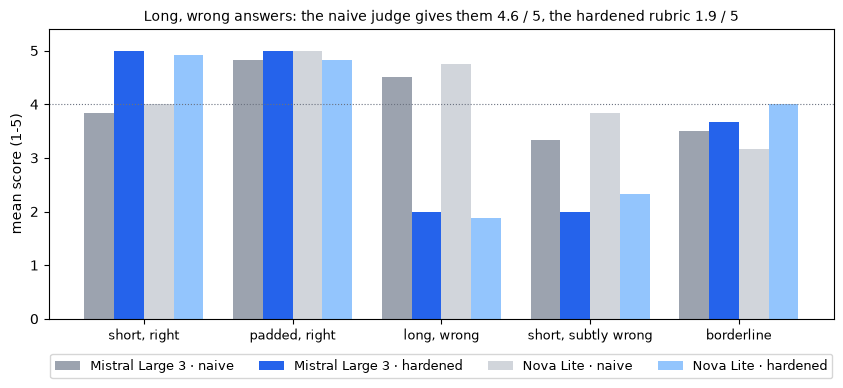

In [16]:
import matplotlib.pyplot as plt
kinds = list(dict.fromkeys(c["kind"] for c in CALIBRATION))
fig, ax = plt.subplots(figsize=(9, 4))
for k, r in enumerate(CALIB_ROWS):
    ax.bar([x + k * 0.2 - 0.3 for x in range(len(kinds))], [r[kd] for kd in kinds], width=0.2,
           label=f"{r['judge']} · {r['rubric']}", color=["#9ca3af", "#2563eb", "#d1d5db", "#93c5fd"][k])
ax.set_xticks(range(len(kinds))); ax.set_xticklabels(kinds, fontsize=9)
ax.set_ylabel("mean score (1-5)"); ax.set_ylim(0, 5.4)
ax.axhline(4, color="#6b7280", lw=0.8, ls=":"); ax.legend(fontsize=9, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
wrong = {rb: statistics.mean(r["long, wrong"] for r in CALIB_ROWS if r["rubric"] == rb) for rb in ("naive", "hardened")}
ax.set_title(f"Long, wrong answers: the naive judge gives them {wrong['naive']:.1f} / 5, "
             f"the hardened rubric {wrong['hardened']:.1f} / 5", fontsize=10)
plt.tight_layout(); plt.show()

> 📊 **How to read this** — one group of four bars per answer kind; grey = naive rubric, blue = hardened, darker =
> Mistral Large 3, lighter = Nova Lite. The dotted line at 4 is the PASS cut-off. A good judge puts *short, right*
> and *padded, right* **above** the line and *long, wrong* and *short, subtly wrong* **below** it. Bars of a wrong
> kind above the line are answers the judge would wave through; *padded* scoring higher than *short* (same facts)
> is verbosity bias.

> **Think about it:** Look at the *long, wrong* column: if the naive judge passes most of the wrong answers, which
> sentence of the hardened prompt do you think did the most work — and how would you *test* that claim?

<details><summary>More questions</summary>

- If the cheap judge scores almost as well, what would make you pay for the expensive one anyway?
- The cheap judge *is* the generator's model. Which bias from slide 37 does that invite, and how would you measure it?
- How many calibration items would you need to tell κ = 0.8 from κ = 0.9?
</details>

> ✅ **Takeaway §2** — Treat a judge like an instrument: calibrate it on human-labelled hard cases, report κ with an
> interval, and read the disagreements. A rubric with a reference answer and an anchored scale is what turns a
> chance-level judge into a useful one.

## 3 · Position bias and verbosity bias in pairwise judging
Pairwise comparison ("is A or B better?") is how A/B evaluations and arenas work. Two experiments, each pair judged
**in both orders** (slide 37: judge each pair twice, swapping the order, and count how often the verdict changes):
- **Position:** two *equally good* answers (our wording vs the reference wording). An unbiased judge's verdict follows
  the answer when the order is swapped — or says TIE. A verdict that stays on the same *slot* is position-driven.
- **Verbosity:** the same correct answer, plain vs padded with filler. Facts are identical, so the right verdict is TIE.

![Judging each pair in both orders: a verdict that follows the answer, one that follows the slot, and a tie](../assets/diagrams/m09_swap.svg)

> 💡 **Concept — position and verbosity bias.** LLM judges are known to prefer the answer in a particular *slot*
> (often the first) and the *longer* answer, independent of content. Both biases are measurable without any human
> labels: show the same pair twice with A and B swapped. A verdict that names the same **answer** both times is
> consistent; one that names the same **slot** both times (A, then A again) was decided by position. If the two
> answers carry the same facts, any consistent winner other than TIE is a bias — for padded vs plain, verbosity.

> 🔑 **Key code** — `pairwise` runs the two orders `(x, y)` and `(y, x)` and maps each "A"/"B" back to the
> **answer** (`"x"`/`"y"`) via `a is x`; a pair is consistent only if both runs name the same answer. `PAIR_HARDENED`
> allows `"TIE"` and says "Ignore the order"; `PAIR_NAIVE` forces a winner.

> ⏱️ The pairwise cell prints nothing for ≈ 25–30 s (192 judge calls, 4 in parallel).

In [17]:
PAIR_NAIVE = """Which answer from a customer support assistant is better?

Question: {q}
Answer A: {a}
Answer B: {b}

Return only JSON: {{"winner": "A" or "B"}}"""

PAIR_HARDENED = """Compare two answers from an insurance support assistant against the reference answer.
Judge ONLY correctness and completeness against the reference. Length, friendliness and filler are not quality. If both
answers state the same facts, the result is TIE. Ignore the order in which the answers are shown.

Question: {q}
Reference answer: {ref}
Answer A: {a}
Answer B: {b}

Think first. Return only JSON: {{"reasoning": "<max 15 words>", "winner": "A" | "B" | "TIE"}}"""

def pairwise(judge_id: str, prompt: str, q: str, ref: str, x: str, y: str) -> tuple[str, str]:
    """Judge (x, y) in both orders. Returns the winner in each order, mapped back to 'x' / 'y' / 'tie'."""
    out = []
    for a, b in ((x, y), (y, x)):                                     # ▶ KEY: the same pair, both orders
        text, _ = converse_text(judge_id, prompt.format(q=q, ref=ref, a=a, b=b), max_tokens=100, section="§3")
        w = str((m.parse_json(text) or {}).get("winner", "?")).upper()
        # ▶ KEY: map the slot ("A"/"B") back to the answer ("x"/"y") - a consistent judge names the same answer twice
        out.append("tie" if w == "TIE" else ("x" if (w == "A") == (a is x) else "y") if w in ("A", "B") else "?")
    return out[0], out[1]

PAIRS = {"position (equal quality)": [(GOLDEN[i][0], GOLDEN[i][1], a, GOLDEN[i][1]) for i, a in SHORT_RIGHT.items()],
         "verbosity (plain vs padded)": [(GOLDEN[i][0], GOLDEN[i][1], a, a + FILLER) for i, a in SHORT_RIGHT.items()]}
jobs = [(j, pname, exp, p) for j in JUDGES for pname in ("naive", "hardened") for exp in PAIRS for p in PAIRS[exp]]
t0 = time.time()
PAIR_OUT = pmap(lambda x: pairwise(x[0], PAIR_NAIVE if x[1] == "naive" else PAIR_HARDENED, *x[3]), jobs)
print(f"{len(PAIR_OUT) * 2} pairwise calls in {time.time() - t0:.0f} s")

192 pairwise calls in 26 s


In [18]:
rows = []
for j in JUDGES:
    for pname in ("naive", "hardened"):
        r = {"judge": m.model_name(j), "prompt": pname}
        for exp in PAIRS:
            got = [o for (jj, pp, ee, _), o in zip(jobs, PAIR_OUT) if (jj, pp, ee) == (j, pname, exp)]
            flips = sum(a != b for a, b in got)                       # verdict changed when only the ORDER changed
            if exp.startswith("position"):
                r["verdict changes with order"] = f"{flips}/{len(got)}"
                r["slot-1 wins (both runs)"] = sum(o == ("x", "y") for o in got)   # first-shown answer won both times
            else:
                r["padded wins both orders"] = f"{sum(o == ('y', 'y') for o in got)}/{len(got)}"
                r["tie both orders"] = f"{sum(o == ('tie', 'tie') for o in got)}/{len(got)}"
        rows.append(r)
m.table(rows)

judge,prompt,verdict changes with order,slot-1 wins (both runs),padded wins both orders,tie both orders
Mistral Large 3,naive,2/12,0,12/12,0/12
Mistral Large 3,hardened,0/12,0,0/12,12/12
Nova Lite,naive,5/12,1,12/12,0/12
Nova Lite,hardened,0/12,0,0/12,12/12


Read the table row by row: a verdict that changes when only the order changed is a coin the judge flipped — **count a win
only if it survives the swap** (the "both orders" columns already do). The naive prompt forces a winner, so between two
equal answers it *must* pick by something irrelevant. Between plain and padded: does it pick the longer one?

> 📊 **How to read this** — four rows: two judges × two prompts, 12 pairs per experiment. Ideal values: **verdict
> changes with order** 0/12, **slot-1 wins (both runs)** 0, **padded wins both orders** 0/12, **tie both orders**
> 12/12. A high *changes with order* count is position bias (the verdict follows the slot); a high *padded wins both
> orders* count is verbosity bias that survives the swap — the swap alone does not remove it, only the prompt does.

> **Think about it:** Your A/B dashboard says the new prompt "wins 70 % of pairwise comparisons". Which two questions
> from this section do you ask before you believe it?

<details><summary>More questions</summary>

- Why is allowing TIE a mitigation and not just a convenience?
- How would you detect *self-preference* (a judge favouring its own model family) with this same harness?
</details>

> ✅ **Takeaway §3** — Never trust a single pairwise verdict: judge both orders, count only wins that survive the
> swap, allow a tie, and tell the judge that length is not quality — then measure that the biases are gone.

## 4 · A release gate for prompt v2 — with error bars
Slides 19–20. The rules are written **before** the test runs. Two samples per question per version (temperature 0.7)
show the run-to-run noise; the hardened judge with the best kappa in §2 scores every answer (pinned: a judge change
must not look like a system change, slide 20).
Statistics: the two samples of a question are not independent, so the bootstrap resamples **questions** (a cluster
bootstrap), not answers — resampling answers would make the interval look narrower than it is.

![The release gate: per-question differences, a cluster bootstrap, and a confidence interval against the non-inferiority margin](../assets/diagrams/m09_gate.svg)

> 💡 **Concept — non-inferiority, not "is it better?".** A prompt change that is meant to change *tone* should not
> make answers *worse*; it does not have to make them better. So the rule is: the lower end of the 95 % CI of
> mean(v2 − v1) must stay above a **margin** (−0.5 judge points) you decided before the test. Point estimates are not
> enough — with 20 questions a difference of a tenth of a point is noise. Rules on contracts and cost sit next to it,
> because a gate that only looks at correctness ships everything it does not measure.

> 💡 **Concept — cluster bootstrap.** The two samples of the same question share the question's difficulty, so they
> are not independent. Average them per question first, then resample the **20 questions** with replacement 5,000
> times and recompute the mean difference. The 2.5th and 97.5th percentiles of those 5,000 means are the 95 % CI.

> 🔑 **Key code** — `GATE` is printed **before** any answer is generated; `temperature=0.7` with `SAMPLES = 2`
> exposes run-to-run noise; `GATE_JUDGE` is picked from §2's kappa table (the calibrated judge, pinned);
> `"score": s or 1` — an unparseable verdict counts as the worst score (fail closed).

> ⏱️ The next cell prints nothing for ≈ 30 s (80 answers + 80 judge calls).

In [19]:
# ▶ KEY: the rules are data, written and printed before the test runs
GATE = {"correctness": ("lower bound of the 95 % CI of mean(v2 − v1) judge score", "> -0.5 (non-inferiority margin)"),
        "contracts":   ("share of v2 answers passing every contract check", ">= v1 share - 5 points"),
        "cost":        ("v2 output tokens per answer", "<= 1.5 x v1")}
m.table([[k, *v] for k, v in GATE.items()], ["rule", "measure", "threshold"], caption="Gate rules (written before the run)")

SAMPLES = 2
work = [(v, qi, s) for v in ("v1", "v2") for qi in range(len(GOLDEN)) for s in range(SAMPLES)]
t0 = time.time()
gen = pmap(lambda w: converse_text(GENERATOR, GOLDEN[w[1]][0], system=PROMPTS[w[0]], temperature=0.7, section="§4"), work)
# ▶ KEY: the judge with the best calibrated kappa, pinned for the whole gate
GATE_JUDGE = next(j for j in JUDGES if m.model_name(j) == max((r for r in CALIB_ROWS if r["rubric"] == "hardened"),
                                                              key=lambda r: r["kappa"])["judge"])
scores = pmap(lambda x: judge(GATE_JUDGE, "hardened", *GOLDEN[x[0][1]], x[1][0], section="§4")["score"],
              list(zip(work, gen)))
RUNS = [{"v": w[0], "qi": w[1], "text": g[0], "out_tokens": g[1]["outputTokens"],
         "score": s or 1,                                                  # unparseable = 1 (fail closed)
         "contract_ok": all(contract(g[0], GOLDEN[w[1]][1]).values())} for w, g, s in zip(work, gen, scores)]
print(f"{len(work)} answers + {len(work)} judge calls ({m.model_name(GATE_JUDGE)}, hardened) in {time.time() - t0:.0f} s")
for qi in (0, 7):
    for v in ("v1", "v2"):
        r = next(r for r in RUNS if r["v"] == v and r["qi"] == qi)
        print(f"{v} [{r['score']}] {r['text'][:150]}")

rule,measure,threshold
correctness,lower bound of the 95 % CI of mean(v2 − v1) judge score,> -0.5 (non-inferiority margin)
contracts,share of v2 answers passing every contract check,>= v1 share - 5 points
cost,v2 output tokens per answer,<= 1.5 x v1


80 answers + 80 judge calls (Mistral Large 3, hardened) in 32 s
v1 [5] The deductible for glass breakage is 100 USD.
v2 [2] I apologize for any inconvenience and thank you for your loyalty to AnyCompany Insurance. Based on your home policy HP-2026, the deductible for a brok
v1 [5] No, you must keep damaged items until the adjuster has seen them.
v2 [5] I'm sorry for any inconvenience, and thank you for your loyalty. Please keep all damaged items until the adjuster has seen them. You may move them out


> 📊 **How to read this** — the first table restates the rules (they were fixed before any answer existed). The
> printed lines show two questions, v1 and v2 side by side, with the judge's score in brackets: compare the
> *content* (same facts?) and the *length* and opening of the v2 answers — that is what the contract and cost rules
> will measure next.

> 🔑 **Key code** — `per_question` averages the two samples of each question (the cluster); `diffs` is one paired
> difference per question; `BOOT` resamples those 20 differences 5,000 times; `BOOT[124]` and `BOOT[4874]` are the
> 2.5th and 97.5th percentiles; each `checks` entry compares a measurement with its rule from `GATE`.

In [20]:
def per_question(v: str, key: str) -> list[float]:
    # ▶ KEY: one value per question - the two samples of a question form a cluster
    return [statistics.mean(r[key] for r in RUNS if r["v"] == v and r["qi"] == qi) for qi in range(len(GOLDEN))]

s1, s2 = per_question("v1", "score"), per_question("v2", "score")
diffs = [b - a for a, b in zip(s1, s2)]
rnd = random.Random(11)
# ▶ KEY: cluster bootstrap - resample the 20 questions, not the 40 answers
BOOT = sorted(statistics.mean(diffs[rnd.randrange(len(diffs))] for _ in diffs) for _ in range(5000))
lo, hi = BOOT[124], BOOT[4874]
c1 = statistics.mean(r["contract_ok"] for r in RUNS if r["v"] == "v1")
c2 = statistics.mean(r["contract_ok"] for r in RUNS if r["v"] == "v2")
t1, t2 = statistics.mean(per_question("v1", "out_tokens")), statistics.mean(per_question("v2", "out_tokens"))
# ▶ KEY: non-inferiority - the CI's LOWER bound must clear the margin, not the point estimate
checks = [("correctness", f"v1 {statistics.mean(s1):.2f} → v2 {statistics.mean(s2):.2f}; diff {statistics.mean(diffs):+.2f}, "
                          f"95 % CI [{lo:+.2f}, {hi:+.2f}]", lo > -0.5),
          ("contracts", f"v1 {c1:.0%} → v2 {c2:.0%}", c2 >= c1 - 0.05),
          ("cost", f"{t1:.0f} → {t2:.0f} output tokens ({t2 / t1 - 1:+.0%})", t2 <= 1.5 * t1)]
m.table([[n, d, "✓ PASS" if ok else "✗ FAIL"] for n, d, ok in checks], ["rule", "measured", "result"])
VERDICT = "PASS" if all(c[2] for c in checks) else "FAIL"
print(f"GATE: {VERDICT}" + ("" if VERDICT == "PASS" else " -> back to development with this report"))
noise = lo < 0 < hi
naive_gate = "ship" if statistics.mean(s2) >= statistics.mean(s1) else "block"
print(f"a point-estimate gate ('ship if v2 mean >= v1 mean') would {naive_gate} on a {statistics.mean(diffs):+.2f} "
      "difference" + (" that is inside the noise (the CI contains 0)" if noise else ""))

rule,measured,result
correctness,"v1 4.67 → v2 4.62; diff -0.05, 95 % CI [-0.60, +0.45]",✗ FAIL
contracts,v1 95% → v2 60%,✗ FAIL
cost,19 → 78 output tokens (+319%),✗ FAIL


GATE: FAIL -> back to development with this report
a point-estimate gate ('ship if v2 mean >= v1 mean') would block on a -0.05 difference that is inside the noise (the CI contains 0)


> 📊 **How to read this** — one row per rule: **measured** is the evidence, **result** the rule's verdict; the gate
> passes only if every row passes. For correctness read the CI, not the means: its lower bound is compared with −0.5.
> For contracts and cost, compare v1 and v2 directly. The last printed line shows what a naive point-estimate gate
> would have done — if the CI contains 0, that gate decided on noise.

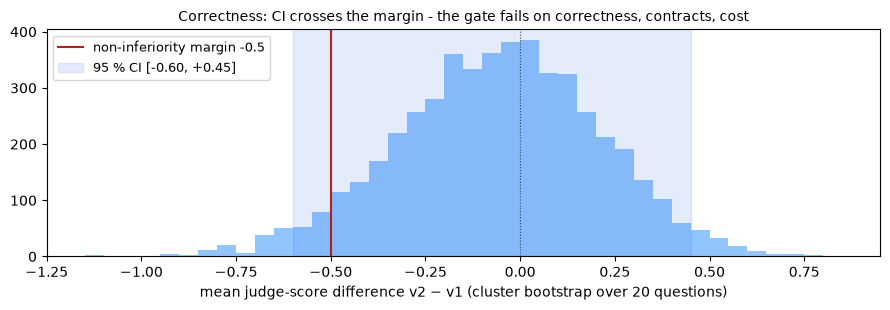

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(BOOT, bins=40, color="#93c5fd")
ax.axvline(-0.5, color="#b91c1c", lw=1.5, label="non-inferiority margin -0.5")
ax.axvspan(lo, hi, color="#2563eb", alpha=0.12, label=f"95 % CI [{lo:+.2f}, {hi:+.2f}]")
ax.axvline(0, color="#374151", lw=0.8, ls=":")
ax.set_xlabel("mean judge-score difference v2 − v1 (cluster bootstrap over 20 questions)"); ax.legend(fontsize=9)
ax.set_title(f"Correctness: CI {'clears' if lo > -0.5 else 'crosses'} the margin - "
             f"the gate {'passes' if VERDICT == 'PASS' else 'fails'} on "
             f"{', '.join(c[0] for c in checks if not c[2]) or 'nothing'}", fontsize=10)
plt.tight_layout(); plt.show()

> 📊 **How to read this** — the histogram is the 5,000 bootstrap means of v2 − v1; the shaded band is the 95 % CI,
> the red line the −0.5 margin, the dotted line 0 (no change). The band entirely right of the red line → correctness
> is non-inferior. The band straddling 0 → no detectable difference either way. The band's width is the price of
> having only 20 questions.

> **Think about it:** Suppose the correctness rule passes and the gate still fails on another rule. Who decides
> whether to ship anyway — and where is that override recorded (slide 19)?

<details><summary>More questions</summary>

- Read the CI's half-width above (20 questions). About how many questions would make it three times narrower?
- What changes in this gate if v2 also made answers 40 % cheaper?
</details>

> ✅ **Takeaway §4** — A release gate is rules written before the run, evaluated with an interval (resampling the
> right unit — the question), next to contract and cost rules. A gate that compares two means decides on noise.

## 5 · The managed version — Amazon Bedrock Evaluations
The jobs from §0 Prep judged the v1 and v2 answers with Nova Pro on four built-in metrics and our custom **Empathy**
metric. `GetEvaluationJob` returns the configuration and the status; the per-record scores land in S3 as JSONL.

> 💡 **Concept — what a finished job leaves behind.** Status goes `InProgress` → `Completed` (or `Failed` /
> `Stopped`). The report in the console is built from files the job wrote under `outputDataConfig.s3Uri`: one
> JSONL line per dataset record with the original `inputRecord` and `automatedEvaluationResult.scores` — per metric a
> normalised `result` (0–1) and `evaluatorDetails` with the judge's written explanation — plus the custom metric's
> definition as the job used it. Because it is your S3 data, you can run your own statistics on it, as below.

> 🔑 **Key code** — `get_evaluation_job(jobIdentifier=…)` for status and timing; the custom metric definition is
> read back from `…/custom_metrics/Empathy.json` (the job API does not echo it).

In [22]:
STATUS = {}
for ver, name in JOBS.items():
    j = find_job(name)
    # ▶ KEY: status, configuration and timing of the managed job
    d = bedrock.get_evaluation_job(jobIdentifier=j["jobArn"]) if j else {}
    STATUS[ver] = d
    if d.get("status") == "Completed":
        when = f"({(d['lastModifiedTime'] - d['creationTime']).total_seconds() / 60:.0f} min)"
    else:
        when = f"(running {(time.time() - d['creationTime'].timestamp()) / 60:.0f} min)" if d else ""
    print(f"{ver}: {d.get('jobName', name)}  {d.get('status', 'not found')}  {when}")
# GetEvaluationJob does not echo the custom metric; the job stores the definition it used next to its output
key = next((o["Key"] for o in s3.list_objects_v2(Bucket=BUCKET, Prefix="m09/results/").get("Contents", [])
            if o["Key"].endswith("custom_metrics/Empathy.json")), None)
if key:
    used = json.loads(s3.get_object(Bucket=BUCKET, Key=key)["Body"].read())["customMetricDefinition"]
    print("custom metric as stored by the job:", used["metricName"], "·", [r["definition"] for r in used["ratingScale"]],
          "· judge", used["evaluatorModelConfig"]["bedrockEvaluatorModels"][0]["modelIdentifier"])
print(f"console: https://{m.REGION}.console.aws.amazon.com/bedrock/home?region={m.REGION}#/eval/model-evaluation")

v1: mlaidp2-m09-1023aad9-support-v1  InProgress  (running 1 min)


v2: mlaidp2-m09-1023aad9-support-v2  InProgress  (running 1 min)


custom metric as stored by the job: Empathy · ['Poor', 'Good', 'Excellent'] · judge us.amazon.nova-pro-v1:0
console: https://us-east-1.console.aws.amazon.com/bedrock/home?region=us-east-1#/eval/model-evaluation


> 🔑 **Key code** — `job_records` finds the job's JSONL files by the **job id** (the last part of the ARN) in the
> output prefix and parses every line; `scores_by_metric` pivots them to *metric → {prompt: score}*, skipping scores
> without a `result` (a judge call that failed for that record).

In [23]:
def job_records(d: dict) -> list[dict]:
    """Every output record of a finished job: the job writes JSONL under <output>/<job name>/<job id>/..."""
    job_id = d["jobArn"].rsplit("/", 1)[-1]
    # ▶ KEY: the job's output files are found by its id under the results prefix
    keys = [o["Key"] for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix="m09/results/")
            for o in page.get("Contents", []) if job_id in o["Key"] and o["Key"].endswith(".jsonl")]
    lines = [ln for k in keys for ln in s3.get_object(Bucket=BUCKET, Key=k)["Body"].read().decode().splitlines()]
    return [json.loads(ln) for ln in lines if ln]

def scores_by_metric(records: list[dict]) -> dict[str, dict[str, float]]:
    """metric -> {prompt: score}."""
    out = {}
    for r in records:
        prompt = r["inputRecord"]["prompt"]
        for s in r["automatedEvaluationResult"]["scores"]:
            if s.get("result") is not None:                           # ▶ KEY: a score without a result = judge error, skipped
                out.setdefault(s["metricName"].replace("Builtin.", ""), {})[prompt] = s["result"]
    return out

DONE = all(STATUS[v].get("status") == "Completed" for v in JOBS)
if DONE:
    RECORDS = {v: job_records(STATUS[v]) for v in JOBS}
    SC = {v: scores_by_metric(RECORDS[v]) for v in JOBS}
    print({v: len(r) for v, r in RECORDS.items()}, "records")
else:
    print("jobs not finished yet - show the configuration above and come back to this section after the break")

jobs not finished yet - show the configuration above and come back to this section after the break


The same gate statistics on the managed scores: per metric, v1 vs v2 on the same 20 prompts (paired), with a bootstrap
interval of the difference. The service normalises every metric to 0–1 (our custom scale 0/1/2 becomes 0/0.5/1).

> 🔑 **Key code** — `paired_ci` is §4's bootstrap again: differences per prompt (paired — same 20 prompts in both
> jobs), resampled 5,000 times. The **reading** column turns the interval into words: entirely below 0 → *worse*,
> entirely above 0 → *better*, otherwise *no detectable change*.

In [24]:
def paired_ci(a: list[float], b: list[float], reps: int = 5000, seed: int = 5) -> tuple[float, float]:
    # ▶ KEY: paired differences per prompt, then the same percentile bootstrap as in §4
    d, rnd = [y - x for x, y in zip(a, b)], random.Random(seed)
    boot = sorted(statistics.mean(d[rnd.randrange(len(d))] for _ in d) for _ in range(reps))
    return boot[int(0.025 * reps)], boot[int(0.975 * reps) - 1]

if DONE:
    rows = []
    for metric in SC["v1"]:
        prompts = [q for q, _ in GOLDEN if q in SC["v1"][metric] and q in SC["v2"].get(metric, {})]
        a, b = [SC["v1"][metric][q] for q in prompts], [SC["v2"][metric][q] for q in prompts]
        lo_, hi_ = paired_ci(a, b)
        rows.append({"metric": metric, "n": len(prompts), "v1": statistics.mean(a), "v2": statistics.mean(b),
                     "v2 − v1": statistics.mean(b) - statistics.mean(a), "95% CI": f"[{lo_:+.2f}, {hi_:+.2f}]",
                     # ▶ KEY: the interval, not the means, decides the reading
                     "reading": "worse" if hi_ < 0 else "better" if lo_ > 0 else "no detectable change"})
    m.table(rows, fmt={"v1": "{:.2f}", "v2": "{:.2f}", "v2 − v1": "{:+.2f}"})
    worse = [r["metric"] for r in rows if r["reading"] == "worse"]
    print(f"{'✓' if 'Empathy' in worse else '✗'} the custom metric detects the scripted v2 tone; "
          f"metrics that got significantly worse: {', '.join(worse) or 'none'}")

> 📊 **How to read this** — one row per metric (4 built-in + Empathy), **n** prompts scored in both jobs, the means
> of v1 and v2 on the 0–1 scale, their difference and its CI, and the **reading**. Look for the metric the change
> was *about* (here the tone, i.e. Empathy) and for metrics that move the *wrong* way. A metric that moves in a
> direction you did not expect is a question about what that metric's judge prompt rewards.

Open the records the judge failed. Every score comes with the judge's explanation — the audit trail slide 38 asks for.
Compare the built-in metrics **on the same answer**.

In [25]:
if DONE:
    for r in RECORDS["v2"]:
        sc = {s["metricName"].replace("Builtin.", ""): s for s in r["automatedEvaluationResult"]["scores"]}
        correct = sc.get("Correctness", {}).get("result")
        if correct is not None and correct < 1:      # a metric can come back without a result (judge error)
            print(f"Q: {r['inputRecord']['prompt']}\nA: {r['inputRecord']['modelResponses'][0]['response'][:260]}")
            print("   " + " · ".join(f"{k} {v['result']:.2f}" if v.get("result") is not None else f"{k} –"
                                     for k, v in sc.items()))
            print(f"   Correctness judge: {sc['Correctness']['evaluatorDetails'][0]['explanation'][:230]}\n")
print("model spend of this notebook run: " + ", ".join(f"{k} ${v:.4f}" for k, v in SPEND.items() if v)
      + f" · total ${sum(SPEND.values()):.3f} (the two evaluation jobs bill their judge tokens separately)")

model spend of this notebook run: §0 $0.0013, §1 $0.0005, §2 $0.0093, §3 $0.0107, §4 $0.0167 · total $0.038 (the two evaluation jobs bill their judge tokens separately)


> **Think about it:** In the records above, do Helpfulness and professional tone stay high on an answer that gets a
> fact wrong? What does that tell you about choosing metrics for *your* gate — and which metric would you never ship
> without?

<details><summary>More questions</summary>

- If the managed job and §4 reach the same verdict, which one would you run on every pull request, and which nightly?
- What would you add to the dataset so the next prompt change cannot fool the job the same way?
</details>

> ✅ **Takeaway §5** — Bedrock Evaluations gives you tested judge prompts, your own custom rubric and an audit trail
> in S3; it does not decide for you — run the same paired statistics on its per-record scores, and choose metrics
> that answer *your* release question.

## Summary — what you built
| Piece | AWS API / pattern | Production next step |
|---|---|---|
| Unit tests + output contracts | plain Python tests, fail-closed parser, numbers-subset oracle | run in CI on every commit; contracts also as runtime checks |
| Calibrated judge | `Converse` judge, Cohen's kappa + bootstrap CI vs human labels | grow the labelled set; re-calibrate on every judge prompt or model change |
| Bias checks | pairwise judging in both orders, TIE allowed | a standing bias test in the judge's own regression suite |
| Release gate | cluster bootstrap CI, non-inferiority margin, contract and token rules | a CI/CD stage that blocks the prompt version and records overrides |
| Managed evaluation | `CreateEvaluationJob` with BYO responses + custom metric, results in S3 | nightly / release-candidate jobs; reports stored next to the prompt version |

## Cleanup — don't skip this
Deletes every evaluation job named `mlaidp2-m09-<run id>…` — also one created in the console (Part 2, step 4). A
running job cannot be deleted: the cell stops it and waits until it is *Stopped* (≈ 1–3 min) before deleting. Then
the bucket with datasets and job output, and the IAM role. **Run it only after Part 2 (console)** — the console demo
opens these jobs and reuses the datasets.

In [26]:
FINAL = ("Completed", "Failed", "Stopped")     # the only states BatchDeleteEvaluationJob accepts

def our_jobs() -> list[dict]:
    """Every job named mlaidp2-m09-<run id>... - including ones the service is still deleting. Paginated."""
    return [j for page in bedrock.get_paginator("list_evaluation_jobs").paginate(nameContains=f"mlaidp2-m09-{RID}")
            for j in page["jobSummaries"]]

for j in our_jobs():
    if j["status"] == "InProgress":             # a running job cannot be deleted: stop it, wait for Stopped
        try:
            bedrock.stop_evaluation_job(jobIdentifier=j["jobArn"]); print(f"  stopping {j['jobName']}")
        except ClientError as e:                # it may have finished in the meantime
            print(f"  {j['jobName']}: {m.error_code(e)}")

not_final = lambda js: [j for j in js if j["status"] not in FINAL + ("Deleting",)]
_ = m.wait_for(our_jobs, until=lambda js: True if not not_final(js) else f"{len(not_final(js))} job(s) still stopping",
               timeout=900, every=10, label="evaluation jobs stopped/finished")

  stopping mlaidp2-m09-1023aad9-support-v1
  stopping mlaidp2-m09-1023aad9-support-v2


  evaluation jobs stopped/finished 2 job(s) still stopping (0 s)


  evaluation jobs stopped/finished ready after 10 s


In [27]:
def delete_jobs(arns: list[str]) -> None:
    """BatchDelete reports per-job errors in the response instead of raising -> raise them so m.retry retries."""
    errors = bedrock.batch_delete_evaluation_job(jobIdentifiers=arns).get("errors", [])
    if errors:
        raise ClientError({"Error": {"Code": "JobNotDeletable", "Message": str(errors)[:300]}}, "BatchDeleteEvaluationJob")

to_delete = [j for j in our_jobs() if j["status"] in FINAL]
for i in range(0, len(to_delete), 25):          # at most 25 jobs per batch call
    arns = [j["jobArn"] for j in to_delete[i:i + 25]]
    m.retry(lambda: delete_jobs(arns), when="JobNotDeletable|Conflict|Validation", tries=12, delay=10)
if to_delete:
    print(f"  deleting {len(to_delete)} evaluation jobs: {', '.join(j['jobName'].split(RID)[-1] for j in to_delete)}")
    try:                                        # 'Deleting' is asynchronous - wait until the list is empty
        m.wait_for(our_jobs, until=lambda js: not js or f"{len(js)} job(s) Deleting", timeout=300, every=10,
                   label="evaluation jobs gone")
    except TimeoutError:
        print("  ⚠ jobs still Deleting after 5 min - the service finishes on its own; the check below lists them")
m.empty_and_delete_bucket(BUCKET)
m.delete_role(ROLE)

  deleting 2 evaluation jobs: -support-v1, -support-v2
  evaluation jobs gone 2 job(s) Deleting (0 s)


  evaluation jobs gone ready after 10 s


  deleted bucket mlaidp2-m09-1023aad9


  deleted role mlaidp2-m09-eval-role


In [28]:
left = [f"{j['jobName']} ({j['status']})" for j in our_jobs()]
left += [b["Name"] for b in s3.list_buckets()["Buckets"] if b["Name"].startswith("mlaidp2-m09")]
try:
    iam.get_role(RoleName=ROLE); left.append(ROLE)
except ClientError:
    pass
print("✓ nothing left" if not left else f"✗ still there: {left}")

✓ nothing left
